In [4]:
import glob
import numpy as np

import pymc as pm
import pytensor.tensor as at

import arviz as az

from scipy.ndimage import uniform_filter, uniform_filter1d
from scipy.interpolate import CubicSpline
from scipy.signal import correlate, correlation_lags
from scipy.signal.windows import tukey

import matplotlib.pyplot as plt
%matplotlib inline

CRYOtools is in development but made freely available on GitHub: [https://github.com/Richardjmorton/CRYOtools](https://github.com/Richardjmorton/CRYOtools)

In [2]:
from CRYOtools.fit import pull_fit_res 
from CRYOtools.util import get_slit_samp, return_obs_info, calculate_cadence, shift_to_v
from CRYOtools.io import find_L1_files, restore_slit_coords

from astropy.io import fits
import astropy.constants as c
import astropy.units as u
from sunpy.coordinates.sun import angular_radius 

# Load DKIST data

In [2]:
path = '/Users/richardmorton/analysis/DKIST/cycle3/pid_3_88/FCEIWI/'

In [17]:
L1_files = find_L1_files(path)
hdr = fits.getheader(L1_files[0], ext=1)

No L1 FITS files found in the directory.


TypeError: 'NoneType' object is not subscriptable

In [9]:
res = return_obs_info([hdr], verbose=False)
n_scan_steps, n_meas_at_step, n_wv, n_along_slit = res

In [4]:
res = restore_slit_coords(path)
hpxy_coords, time_coords, spec_coords = res

cad = calculate_cadence(time_coords)

In [5]:
slit_samp, _ = get_slit_samp(hpxy_coords, 1, verbose=False)

In [6]:
dy_km = c.R_sun.to(u.km)/angular_radius('20250323_211742')*slit_samp*u.arcsec
print(dy_km)

86.80738670145047 km


In [7]:
fit_res, _ = pull_fit_res(path)

Getting fit data:   0%|          | 0/3799 [00:00<?, ?it/s]

Convert line shifts to Doppler velocities and show.

In [11]:
dopp_vel = shift_to_v(fit_res[1], spec_coords=spec_coords).value

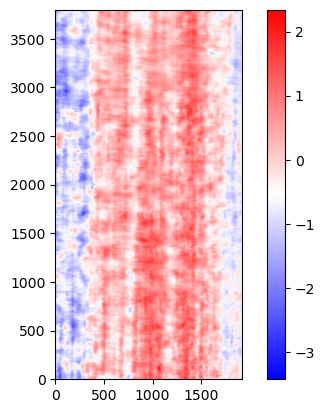

In [12]:
plt.imshow(dopp_vel- np.mean(dopp_vel), cmap='bwr', origin='lower')
plt.colorbar()

# Fourier transform

Subtract mean and apply Tukey window before Fourier transforming.

In [13]:
window = tukey(dopp_vel.shape[0], alpha=0.1)
dopp_fft = []

for i in range(dopp_vel.shape[1]):
    x = dopp_vel[:,i]
    x= x-x.mean()
    dopp_fft.append(np.fft.rfft(x*window,axis=0))

dopp_fft = np.array(dopp_fft).T

freq = np.fft.rfftfreq(dopp_vel.shape[0], cad)
f_s = 1./cad # sampling frequency
s2 = (window**2).sum() # windowing property used for nomalisation

Bootstrap mean of the power spectra to estimate uncertaintity.

In [14]:
def bootstrap_gen(ft_arr):
    bootstrap_vals = []
    n_boots = 500
    for i in range(n_boots):
        index = rng.integers(0,high=ft_arr.shape[1], size=ft_arr.shape[1])
        bootstrap_vals.append((np.abs(ft_arr[:, index])**2).mean(axis=1))
        
    return np.array(bootstrap_vals)


Comparison shows classic standard error formula and bootstrap are very close.

In [15]:
rng = np.random.default_rng(12345)
power_mean = (np.abs(dopp_fft[:,1400:])**2).mean(axis=1)
power_mean_std = (np.abs(dopp_fft[:,1400:])**2).std(axis=1)/np.sqrt(dopp_fft[:,1400:].shape[1])
power_err = bootstrap_vals.std(axis=0)

However, when plotting this error estimate the variability in the power spectrum is clearly under estimated. We know that the Doppler signals are correlated over a a number of pixels (which is frequency dependent), hence each pixel is not an indepdent sample of the power. We can attempt to correct for this by dividing the number of pixels in the sample, $N$ by the estimated number of correlated pixels, $N_{cor}$, which represents the distance at which the correaltion drops by $1/e$.

Hence
$$
\sigma_{mean}=\sqrt{N_{cor}}\frac{\sigma_{std}}{\sqrt{N}}
$$

# Calcluate correlation between time-series as a function of frequency

Neighbouring Doppler velocity time-series are coherent. This will lead to an underestimate of true uncertaintity in mean power. we calculate the coherence distance (in pixels) as a function of frequency. This is used to estimate $N_{cor}$

In [1]:
dopp_fft_no_win = []
for i in range(dopp_vel.shape[1]):
    x = dopp_vel[:,i]
    x= (x-x.mean())/x.std()
    dopp_fft_no_win.append(np.fft.rfft(x,axis=0))
dopp_fft_no_win = np.array(dopp_fft_no_win).T

NameError: name 'dopp_vel' is not defined

In [17]:
corr_coffs_four = []
smoothing = 10

cor_len_pix = 120

for i in range(dopp_vel.shape[1]-cor_len_pix):
    inner = np.zeros((cor_len_pix,freq.shape[0]-1))
    x = dopp_fft_no_win[1:,i]
    for j in range(cor_len_pix):
        y = dopp_fft_no_win[1:,i+j]
        F_12 = np.abs(uniform_filter1d(x * np.conj(y), smoothing))
        F_1 = uniform_filter1d(np.real(x*np.conj(x)), smoothing)
        F_2 = uniform_filter1d(np.real(y*np.conj(y)), smoothing)
        inner[j,:] = F_12**2/F_1/F_2
    corr_coffs_four.append(inner)

In [18]:
threshold = np.exp(-1)
n_freq = freq[1:].shape[0]

cor_loc = []
corr_coffs_mean = np.median(corr_coffs_four[1400:], axis=0)**0.5
for i in range(n_freq):
    xs = corr_coffs_mean[:,i]
    ind = np.argmax(xs <= threshold)
    if ind > 0:
        cor_loc.append([i,ind])

cor_loc_all = []
corr_coffs_mean = np.median(corr_coffs_four, axis=0)**0.5
for i in range(1, n_freq):
    xs = corr_coffs_mean[:,i]
    ind = np.argmax(xs <= threshold)
    if ind > 0:
        cor_loc_all.append([i,ind])


In [19]:
cor_loc = np.array(cor_loc)
cor_loc_all = np.array(cor_loc_all)

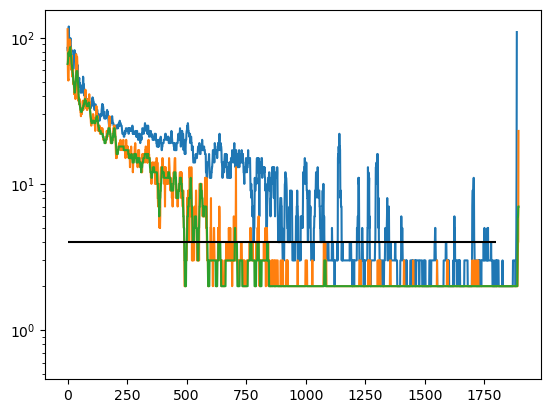

In [76]:
plt.plot(cor_loc_all[:,1])
plt.plot(cor_loc[:,1])
plt.plot(uniform_filter1d(cor_loc[:,1],10))
plt.yscale('log')

plt.hlines(4, 0,1800, color='black')

In [79]:
cor_loc_all[1000:,1].mean()*slit_samp

0.45371994728680604

In [20]:
# not all frequencies have a correlation value
vals = freq[1:][cor_loc[:,0]]
ind = np.where(freq[1:] == vals[0])[0][0]

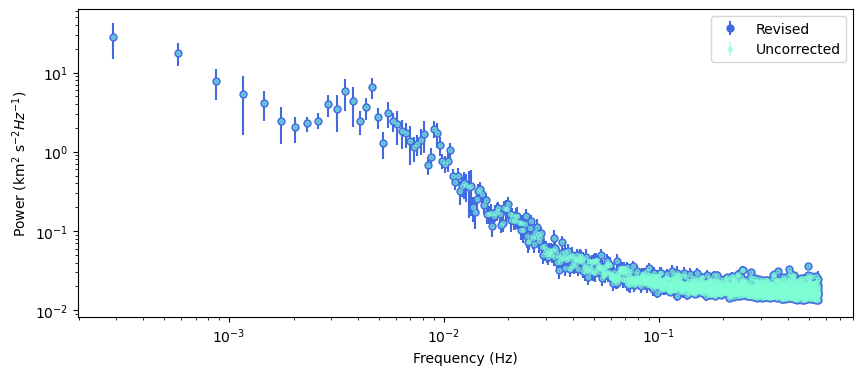

In [21]:
fig = plt.figure(figsize=(10,4))

x = freq[1:]
y = power_mean[1:]
yerr = np.zeros((x.shape[0]))
yerr[0:ind] = cor_loc[0,1]**0.5*power_mean_std[1:ind+1] # correct low frequencies with last good estimate
yerr[ind:] = (cor_loc[:,1])**0.5*power_mean_std[1:][cor_loc[:,0]]

plt.errorbar(x, y/f_s/s2, yerr=yerr/f_s/s2, fmt='.', label='Revised', color='royalblue', markersize=10)
plt.errorbar(freq, power_mean/f_s/s2, yerr=power_mean_std/f_s/s2, fmt='.', alpha=0.5, color='aquamarine', label='Uncorrected')
plt.yscale('log')
plt.xscale('log')
plt.ylabel(r'Power (km$^2$ s$^{-2} Hz^{-1}$)')
plt.xlabel('Frequency (Hz)')
plt.legend()


As can be seen from the above plot, the original error bars are vanishingly small. The corrected ones appear to better represent the variability.

# Bayesian Modelling

Fitting only potential open field region

# Interpret power spectrum

Here we pull in observations and theory to interpret power spectrum

Define function that calculates the transmissivity of Alfven waves based on Soler et al. 2019.

In [22]:
from scipy.special import erf

def transmit_curve(B_phot, freq):
    # Function from Soler et al. 2019
    a_100 = 0.543034+0.003699*B_phot-1.0527*1e-6*B_phot**2
    mu = 0.4019 +0.0008743*B_phot-2.410*1e-7*B_phot**2
    sig = 0.6007-0.00007139*B_phot+3.468*1e-9*B_phot**2
    alpha = -4.4306+0.002966*B_phot-8.4372*1e-7*B_phot**2
    
    x = np.log10(freq)
    
    exp_term = a_100/100/np.sqrt(2*np.pi*sig**2)*np.exp(-(x-mu)**2/2/sig**2)
    other = erf(alpha/np.sqrt(2)*(x-mu)/sig)
    return exp_term*(1+other)


Check function is working

Text(0.5, 0, 'log 10 f (mHz)')

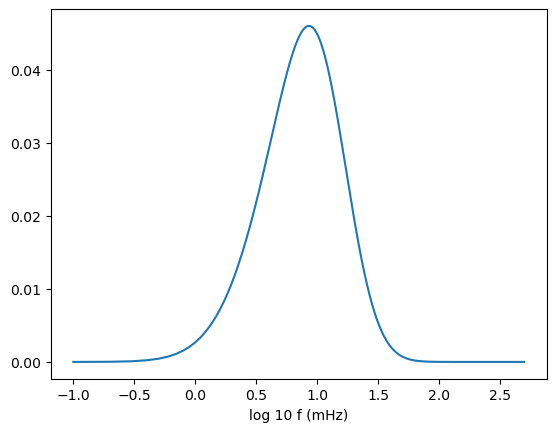

In [23]:
freq_plot = np.arange(0.1,500,0.1) # mhz
plt.plot(np.log10(freq_plot), transmit_curve(2000, freq_plot))
plt.xlabel('log 10 f (mHz)')

Power spectrum of magnetic bright point motions from Chitta et al. 2012. Use functional form fitted to the auto-correlation function.

Can combine this with the transmission profiles from Soler et al. 

1.281670025438889


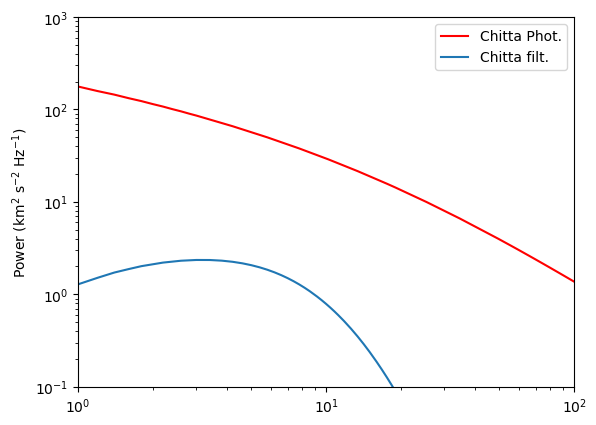

In [25]:
t_len = 5000
def auto_c(k, t_len): 
    t = np.arange(-t_len,t_len)
    a= 0
    b=(1.77+1.45)/2
    tau=(30+22.5)/2
    return a+ b/(1+(np.abs(t)/tau)**k)

chit_freq = np.fft.rfftfreq(t_len)[1:]
chit_pow = np.abs(np.fft.rfft(auto_c((0.7+0.9)/2, t_len))[0:t_len//2+1])

chit_trans_1k = transmit_curve(1000, chit_freq*1e3)*chit_pow[1:]
chit_trans_12k = transmit_curve(1200, chit_freq*1e3)*chit_pow[1:]
chit_trans_15k = transmit_curve(1500, chit_freq*1e3)*chit_pow[1:]
#plt.plot(np.fft.rfftfreq(t_len)*1e3,np.abs(np.fft.fft(auto_c(2))[0:t_len//2+1]))


plt.plot(chit_freq*1e3, chit_pow[1:], color='red', label='Chitta Phot.')
plt.plot(chit_freq*1e3, chit_trans_1k, label='Chitta filt.')
plt.yscale('log')
plt.xscale('log')
plt.ylabel(r'Power (km$^2$ s$^{-2}$ Hz$^{-1}$)')
plt.ylim(0.1,1e3)
plt.xlim(0.001*1e3,0.1*1e3)
plt.legend()
print(np.sqrt(chit_pow.sum()/t_len))

In [26]:
t_len = dopp_vel.shape[0]
chit_freq_mod = np.fft.rfftfreq(t_len, cad)[1:]
chit_pow_mod = np.abs(np.fft.fft(auto_c((0.7+0.9)/2, t_len))[0:t_len//2+1])

Define model in PyMC

In [27]:
def double_gauss_pm(x, p1,p2,p3,p4,p5,p6):
    gauss_1 = p1*at.exp(-(x-p2)**2/2/p3**2)
    gauss_2 = p4*at.exp(-(x-p5)**2/2/p6**2)
    return gauss_1 + gauss_2

def transmit_curve_pm(B_phot, freq):
    # Function from Soler et al. 2019
    a_100 = 0.543034+0.003699*B_phot-1.0527*1e-6*B_phot**2
    mu = 0.4019 +0.0008743*B_phot-2.410*1e-7*B_phot**2
    sig = 0.6007-0.00007139*B_phot+3.468*1e-9*B_phot**2
    alpha = -4.4306+0.002966*B_phot-8.4372*1e-7*B_phot**2
    
    x = at.log10(freq)
    
    exp_term = a_100/100/at.sqrt(2*at.pi*sig**2)*at.exp(-(x-mu)**2/2/sig**2)
    other = pm.math.erf(alpha/at.sqrt(2)*(x-mu)/sig)
    return exp_term*(1+other)

def pow_law_mod(x,p1,p2,p3):
    xlg = at.log(x)
    return p1*at.pow(x,-p2)+at.exp(p3)

def pow_law_mod_np(x,p1,p2,p3):
    xlg = np.log(x)
    return p1*np.power(x,-p2)+np.exp(p3)

with pm.Model() as model_bump:
   
    #prior
    slope = pm.Normal('slope', 1, 0.5)
    amp = pm.HalfNormal('amp', 1)
    const = pm.Normal('const', 4, 0.5)
    gauss_amp = pm.Normal('gauss_amp', 4, 1)
    gauss_mu = pm.Normal('gauss_mu', 4,0.5) 
    gauss_sd = pm.HalfNormal('gauss_sd', 0.5)

    gauss_amp2 = pm.Normal('gauss_amp2', 4,1)
    gauss_mu2 = pm.Normal('gauss_mu2', 9,0.5) 
    gauss_sd2 = pm.HalfNormal('gauss_sd2', 0.5)

    tc_amp = pm.Normal('tc_amp', 3, 1)
    B_phot = pm.Normal('B_phot', 3.1, 0.1)
    
    #sig_mod = pm.Uniform('sig_mod',0,10)
    
    pow_law = pow_law_mod(x, amp, slope, const)
    bump = double_gauss_pm(x*1e3, 10**gauss_amp,gauss_mu,gauss_sd,10**gauss_amp2,gauss_mu2,gauss_sd2)
    bump += 10**tc_amp*transmit_curve_pm(10**B_phot, x*1e3)*chit_pow_mod[1:]
    mod_b = pm.Deterministic('mod_b', bump)
    mod = pm.Deterministic('mod',pow_law+bump) # keep track of model this time
    
    
    # likelihood
    obs1 = pm.Normal('obs1',mu=mod, sigma=yerr, observed=y)

Plot prior predictive distribution to check priors.


In [28]:
with model_bump:
    prior_checks = pm.sample_prior_predictive(1000)

Sampling: [B_phot, amp, const, gauss_amp, gauss_amp2, gauss_mu, gauss_mu2, gauss_sd, gauss_sd2, obs1, slope, tc_amp]


/var/folders/5d/4rwmvh111bs67rvjkr6rfft40000gp/T/ipykernel_44389/758825075.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 0, 'Frequency')

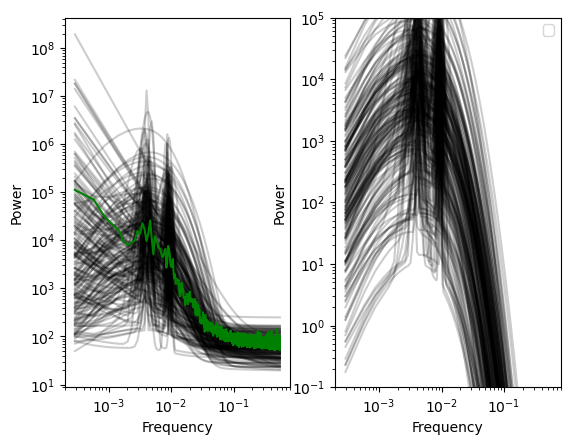

In [29]:
model_pred = prior_checks.prior['mod']
model_bump_pred = prior_checks.prior['mod_b']

fig,ax = plt.subplots(1,2)

# prior predictive models
ax[0].plot(x, model_pred[:,0].squeeze(), color='black', label='prior_pred', alpha=0.2)
ax[0].plot(x, model_pred[:,1:200].T.squeeze(), color='black', alpha=0.2)

ax[0].plot(x, y, color='green', label='data')
ax[0].set_yscale('log')
ax[0].set_xscale('log')

ax[0].set_ylabel('Power')
ax[0].set_xlabel('Frequency')
plt.legend()

ax[1].plot(x, model_bump_pred[:,0].squeeze(), color='black', label='prior_pred', alpha=0.2)
ax[1].plot(x, model_bump_pred[:,1:200].T.squeeze(), color='black', alpha=0.2)

#ax[1].plot(x[1:], y[1:]-pow_law_only[1:], color='green', label='data')
ax[1].set_yscale('log')
ax[1].set_xscale('log')
ax[1].set_ylim(1e-1,1e5)

ax[1].set_ylabel('Power')
ax[1].set_xlabel('Frequency')

Start sampler at MAP values. Find MAP values

In [30]:
import pymc_ext as pmx

with model_bump:
    soln = pmx.optimize()
    soln = pmx.optimize(soln)

KeyboardInterrupt: 

Sample the posterior

In [93]:
with model_bump:
    trace = pm.sample(draws=2000, tune=1000, return_inferencedata=True, initvals=soln)

Auto-assigning NUTS sampler...
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [slope, amp, const, gauss_amp, gauss_mu, gauss_sd, gauss_amp2, gauss_mu2, gauss_sd2, tc_amp, B_phot]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 88 seconds.
There were 26 divergences after tuning. Increase `target_accept` or reparameterize.


Save and load data

In [114]:
trace.to_netcdf('PSP23_MCMC_alfven_trans_model.nc')

'PSP23_MCMC_alfven_trans_model.nc'

In [3]:
trace = az.from_netcdf('PSP23_MCMC_alfven_trans_model.nc')

Examine the posterior summary

In [4]:
az.summary(trace, var_names=['slope', 'amp', 'const', 'gauss_amp', 'gauss_mu', 'gauss_sd',
                             'tc_amp','B_phot'], hdi_prob=0.99)

,mean,sd,hdi_0.5%,hdi_99.5%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
slope,1.511,0.033,1.420,1.589,0.001,0.001,2989.0,3089.0,1.0
amp,0.673,0.065,0.525,0.866,0.001,0.001,2907.0,2925.0,1.0
const,4.156,0.004,4.144,4.166,0.000,0.000,3491.0,3899.0,1.0
gauss_amp,3.790,0.238,2.952,4.576,0.006,0.014,2506.0,1702.0,1.0
gauss_mu,4.266,0.353,3.389,5.262,0.006,0.005,3801.0,2698.0,1.0
gauss_sd,0.942,0.401,0.000,1.808,0.010,0.005,1715.0,1630.0,1.0
tc_amp,3.047,0.120,2.769,3.316,0.003,0.001,1560.0,3275.0,1.0
B_phot,3.103,0.062,2.983,3.305,0.002,0.001,1577.0,2536.0,1.0


Plot some of the posteriors

array([[<Axes: title={'center': 'gauss_mu'}>,
        <Axes: title={'center': 'gauss_mu'}>],
       [<Axes: title={'center': 'gauss_mu2'}>,
        <Axes: title={'center': 'gauss_mu2'}>]], dtype=object)

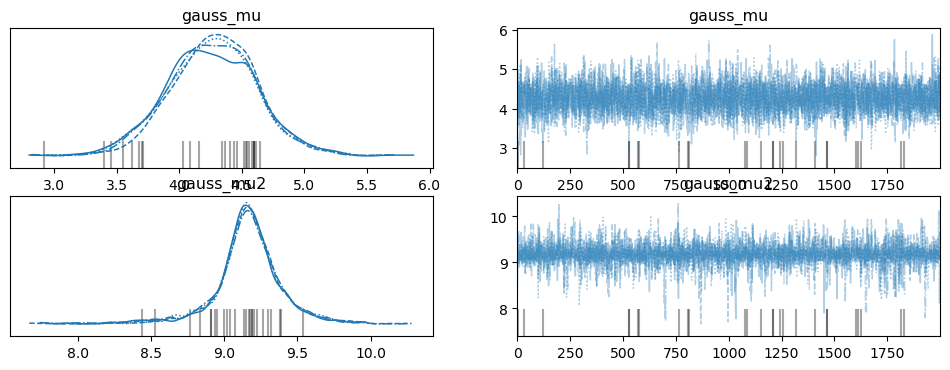

In [33]:
az.plot_trace(trace, var_names=['gauss_mu', 'gauss_mu2'])

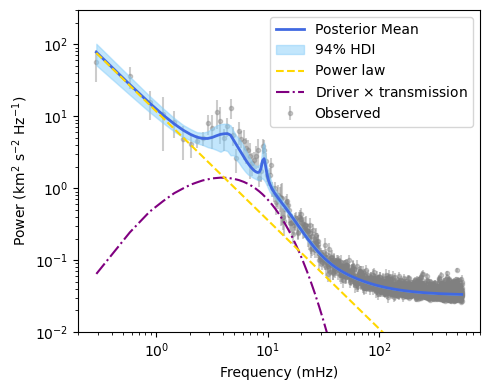

In [34]:
posterior = trace.posterior['mod'].data.reshape(4,2000,power_mean[1:].shape[0])#/f_s/s2
mean_mod = posterior.mean(axis=0).mean(axis=0)
hdi_all = az.hdi(posterior, hdi_prob=0.94)

noise = np.exp(trace.posterior['const'].data.mean())
amp = trace.posterior['amp'].data.mean()
slope = trace.posterior['slope'].data.mean()
pow_law_only = amp*x**(-slope)#+noise

plt.figure(figsize=(5,4))

plt.errorbar(x*1e3, 2.*y/s2/f_s, yerr=2.*yerr/f_s/s2, fmt='.', label='Observed', alpha=0.4, color='gray', zorder=1)
_ = plt.plot(x*1e3, 2.*mean_mod/s2/f_s, color='royalblue',label='Posterior Mean', lw=2,zorder=3)
_ = plt.fill_between(x*1e3, 2.*hdi_all[:,0]/s2/f_s, 2.*hdi_all[:,1]/s2/f_s, 
                          color='lightskyblue', alpha=0.5, label='94% HDI', zorder=2)

_ = plt.plot(x*1e3, 2.*pow_law_only/s2/f_s, color='gold',label='Power law',linestyle='--', zorder=3)
_ = plt.hlines(2.*noise/s2/f_s, x[0]*1e3,x[-1]*1e3, color='black',label='Noise',linestyle='--', alpha=0.3)


tcamp = trace.posterior['tc_amp'].data.mean()
b_phot = trace.posterior['B_phot'].data.mean()
plt.plot(x*1e3, 2.*10**tcamp*transmit_curve(10**b_phot, x*1e3)*chit_pow_mod[1:]/t_len, 
         color='purple', linestyle='-.', label=r'Driver $\times$ transmission')

plt.ylabel(r'Power (km$^2$ s$^{-2}$ Hz$^{-1}$)')
plt.xlabel('Frequency (mHz)')

plt.xscale('log')
plt.yscale('log')

plt.ylim(1e-2,3e2)

plt.legend()
plt.tight_layout()
plt.savefig('PSP23_full_model_bayesian_fit.png',dpi=300)

Here we estimate how much of the power enhancement comes from each component.

In [35]:
# Calculate each curve for posterior draw
trans_curv = []
gauss_curv_1 = []
gauss_curv_2 = []
power_law = []

x = freq[1:]

for i in range(4):
    for j in range(2000):
        val= 10**trace.posterior['tc_amp'][i,j].data*transmit_curve(10**trace.posterior['B_phot'][i,j].data, x*1e3)*chit_pow_mod[1:]
        trans_curv.append(val)

        val = 10**trace.posterior['gauss_amp'][i,j].data*np.exp(-(x*1e3-trace.posterior['gauss_mu'][i,j].data)**2/2/trace.posterior['gauss_sd'][i,j].data**2)
        gauss_curv_1.append(val)

        val = 10**trace.posterior['gauss_amp2'][i,j].data*np.exp(-(x*1e3-trace.posterior['gauss_mu2'][i,j].data)**2/2/trace.posterior['gauss_sd2'][i,j].data**2)
        gauss_curv_2.append(val)

        val = trace.posterior['amp'][i,j].data*np.power(x,-trace.posterior['slope'][i,j].data)
        power_law.append(val)

Plot example set of data 

(0.1, 100000.0)

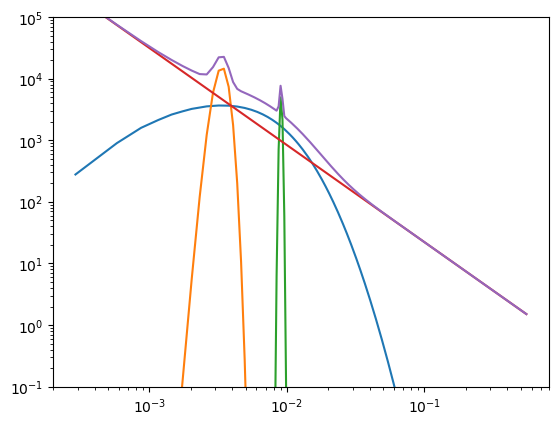

In [31]:
# 
i = 100
plt.plot(x, trans_curv[i])
plt.plot(x, gauss_curv_1[i])
plt.plot(x, gauss_curv_2[i])
plt.plot(x, power_law[i])
plt.plot(x, trans_curv[i]+gauss_curv_1[i]+gauss_curv_2[i]+power_law[i])
plt.xscale('log')
plt.yscale('log')
plt.ylim(1e-1,1e5)

In [36]:
perc_vals = []

for a, b, c in zip(trans_curv, gauss_curv_1, gauss_curv_2):
    total = a.sum() + b.sum() + c.sum()
    perc_vals.append([a.sum()/total, b.sum()/total, c.sum()/total])

In [38]:
perc_vals = np.array(perc_vals)

print(np.median(perc_vals,axis=0))
print(np.mean(perc_vals,axis=0))
print(perc_vals.std(axis=0))

[0.59470734 0.3348984  0.07045541]
[0.60247427 0.32557954 0.07194618]
[0.14486133 0.13343341 0.03239458]


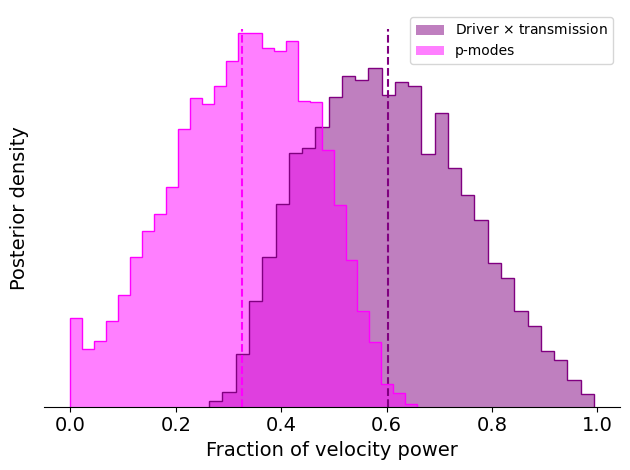

In [39]:
fig, ax = plt.subplots()
ax.hist(perc_vals[:,0], density=True, bins='scott', label=r'Driver $\times$ transmission', alpha=0.5, color='purple', stacked=True)
ax.hist(perc_vals[:,0], density=True, bins='scott', histtype='step', color='purple')
plt.vlines(perc_vals[:,0].mean(),0, 2.8, color='purple', linestyle='--')

ax.hist(perc_vals[:,1], density=True, bins='scott', label='p-modes', color='fuchsia', alpha=0.5)
ax.hist(perc_vals[:,1], density=True, bins='scott', color='fuchsia', histtype='step')
plt.vlines(perc_vals[:,1].mean(),0, 2.8, color='fuchsia', linestyle='--')
#_ = ax.hist(perc_vals[:,2], density=True, bins='scott', label='6 mHz', color='skyblue', alpha=0.5, stacked=True)
#_ = ax.hist(perc_vals[:,2], density=True, bins='scott', color='skyblue', histtype='step')
ax.set_xlabel('Fraction of velocity power',fontsize=14)
ax.set_ylabel('Posterior density', fontsize=14)

ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

# Optional: adjust ticks if left spine is gone
ax.yaxis.set_ticks_position('none')
ax.yaxis.set_ticklabels([])
ax.xaxis.set_tick_params(labelsize=14)
plt.legend()
plt.tight_layout()
plt.savefig('PSP23_perc_source_hist.pdf',dpi=300)

In [2]:
%load_ext watermark

In [5]:
watermark -iv

arviz     : 0.21.0
matplotlib: 3.10.0
numpy     : 1.26.4
pymc      : 5.16.1
pytensor  : 2.23.0
scipy     : 1.12.0

